# Demo Khử Nhiễu Ảnh Bằng Thuật Toán Non-Local Means (NLM)
**Bài tập lớn môn Xử lý ảnh - Nhóm 10 (Lớp E23TTNT02)**

Notebook này thực hiện demo và đánh giá thực nghiệm:
1. Nạp ảnh chuẩn và mô phỏng nhiễu Gauss (AWGN).
2. Gọi hàm khử nhiễu `nlm_denoise` với cả 3 backend: `naive`, `vectorized`, và `jit`.
3. Hiển thị ảnh gốc, ảnh nhiễu và các ảnh đã lọc trên cùng một hàng bằng `matplotlib`.
4. Bảng so sánh định lượng các chỉ số PSNR và SSIM.
5. Khảo sát thực nghiệm chất lượng lọc qua dải độ lệch chuẩn nhiễu $\sigma \in \{10, 15, 25, 50\}$ và vẽ biểu đồ.

In [26]:
import os
import sys
from pathlib import Path

REPO_URL = "https://github.com/thang260205/DIP-2026-2027.git"
PROJECT_DIR = Path("/content/DIP-2026-2027")  # trên Colab; trên máy local bỏ qua khối clone

# Chỉ clone khi đang chạy trên Colab và chưa có thư mục
if not PROJECT_DIR.exists() and Path("/content").exists():
    os.system(f"git clone -q {REPO_URL} {PROJECT_DIR}")

def find_project_root():
    """Tìm thư mục chứa package nlm/ (chạy được trên máy local và Colab)."""
    candidates = [Path.cwd(), *Path.cwd().parents, PROJECT_DIR]
    for path in candidates:
        if (path / "nlm" / "__init__.py").is_file():
            return path.resolve()
    return None

project_root = find_project_root()
if project_root is None:
    raise FileNotFoundError(
        "Không tìm thấy package 'nlm'. Kiểm tra lại git clone hoặc vị trí notebook."
    )

os.chdir(project_root)
sys.path.insert(0, str(project_root))
print("Project root:", project_root)

# Cài thư viện (bỏ qua nếu đã có)
os.system("pip install -q -r requirements.txt")

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from skimage import img_as_float
from skimage.color import rgb2gray
from skimage.io import imread

from nlm import nlm_denoise
from nlm.utils import to_float
from nlm.noise import add_awgn
from nlm.metrics import mse, psnr, ssim

Project root: /content/DIP-2026-2027


## 1. Nạp ảnh gốc và thêm nhiễu AWGN ($\sigma = 25/255$)
Nạp ảnh TIFF trong thư mục `images`, chuyển ảnh RGB sang ảnh mức xám và chuẩn hóa về float trong khoảng [0, 1], sau đó thêm nhiễu Gauss với seed cố định.

In [27]:
!cd /content/DIP-2026-2027 && git pull
!ls /content/DIP-2026-2027/images

Already up to date.
'Fig0638(a)(lenna_RGB).tif'


In [28]:
from skimage.io import imread
from skimage.color import rgb2gray
from skimage.transform import resize
from skimage import img_as_float
import time

lena_path = PROJECT_DIR / "images" / "Fig0638(a)(lenna_RGB).tif"
lena_rgb = imread(lena_path)
clean_img = img_as_float(rgb2gray(lena_rgb))

if clean_img.shape != (512, 512):
    clean_img = resize(clean_img, (512, 512), anti_aliasing=True)

sigma_25 = 25.0 / 255.0
noisy_img = add_awgn(clean_img, sigma=sigma_25, seed=42)

print("Kích thước ảnh:", clean_img.shape)
print(f"PSNR ảnh nhiễu: {psnr(clean_img, noisy_img):.2f} dB")
print(f"SSIM ảnh nhiễu: {ssim(clean_img, noisy_img):.4f}")

results = {}
for backend in ["jit", "vectorized", "naive"]:
    t0 = time.perf_counter()
    out = nlm_denoise(noisy_img, f=2, t=5, h=0.1, sigma=sigma_25, backend=backend)
    elapsed = time.perf_counter() - t0
    results[backend] = out
    print(f"{backend:>10}: {elapsed:8.2f} s | PSNR {psnr(clean_img, out):.2f} dB | SSIM {ssim(clean_img, out):.4f}")

Kích thước ảnh: (512, 512)
PSNR ảnh nhiễu: 20.80 dB
SSIM ảnh nhiễu: 0.2877
       jit:     2.29 s | PSNR 30.23 dB | SSIM 0.7699
vectorized:     1.45 s | PSNR 30.23 dB | SSIM 0.7699
     naive:   331.74 s | PSNR 30.23 dB | SSIM 0.7699


## 2. Khử nhiễu với 3 backend: `naive`, `vectorized`, và `jit`
Gọi hàm `nlm_denoise` với các tham số $f=2$ (patch $5 \times 5$), $t=5$ (vùng tìm kiếm $11 \times 11$), $h=0.12$.

In [29]:
# Thiết lập tham số lọc NLM
f_param = 2
t_param = 5
h_param = 0.12

# Gọi khử nhiễu với backend naive, vectorized và jit
denoised_naive = nlm_denoise(noisy_img, f=f_param, t=t_param, h=h_param, sigma=sigma_25, backend="naive")
denoised_vectorized = nlm_denoise(noisy_img, f=f_param, t=t_param, h=h_param, sigma=sigma_25, backend="vectorized")
denoised_jit = nlm_denoise(noisy_img, f=f_param, t=t_param, h=h_param, sigma=sigma_25, backend="jit")

print("Đã hoàn thành khử nhiễu trên cả 3 backend!")

Đã hoàn thành khử nhiễu trên cả 3 backend!


## 3. Hiển thị ảnh gốc, ảnh nhiễu và ảnh khôi phục trên một hàng
Sử dụng `matplotlib` để hiển thị trực quan và so sánh chất lượng khử nhiễu.

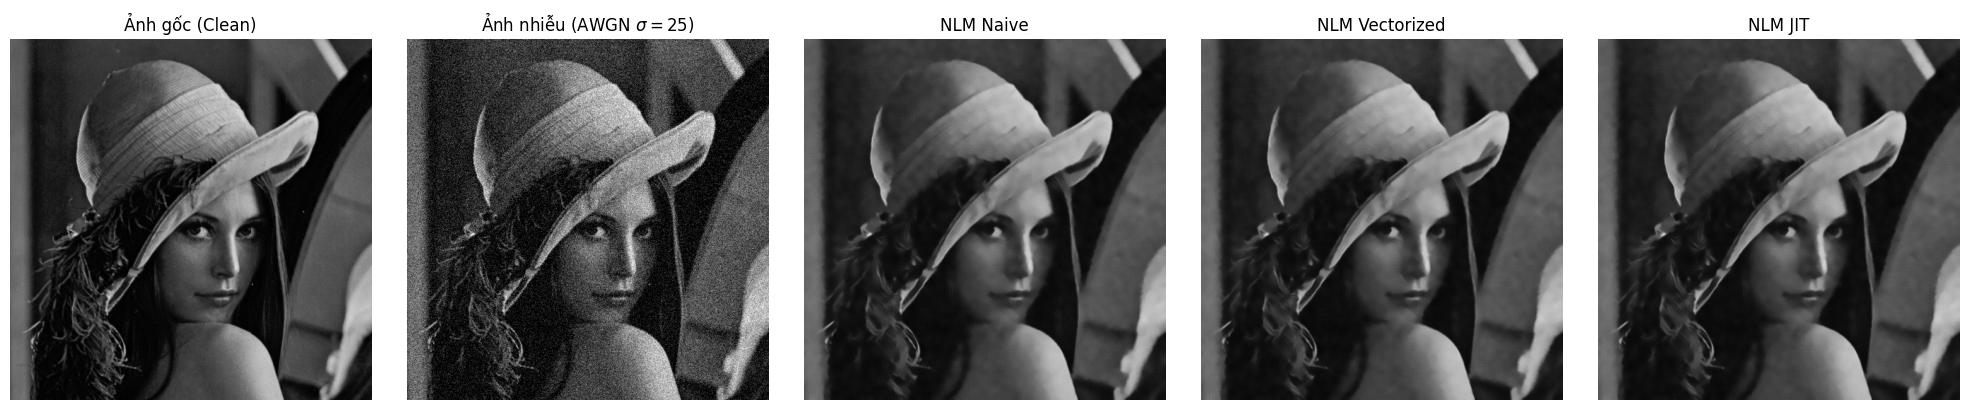

In [30]:
# Hiển thị ảnh gốc, ảnh nhiễu và các ảnh sau lọc trên một hàng
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

images = [
    ("Ảnh gốc (Clean)", clean_img),
    (r"Ảnh nhiễu (AWGN $\sigma=25$)", noisy_img),
    ("NLM Naive", denoised_naive),
    ("NLM Vectorized", denoised_vectorized),
    ("NLM JIT", denoised_jit),
]

for ax, (title, im) in zip(axes, images):
    ax.imshow(im, cmap="gray", vmin=0.0, vmax=1.0)
    ax.set_title(title, fontsize=12)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 4. Bảng chỉ số PSNR và SSIM
Đo lường độ nâng cao chất lượng ảnh bằng bảng định lượng PSNR (dB) và SSIM.

In [31]:
# Lập bảng đánh giá PSNR và SSIM cho từng ảnh
results = []
items = [
    ("Ảnh nhiễu", noisy_img),
    ("NLM Naive", denoised_naive),
    ("NLM Vectorized", denoised_vectorized),
    ("NLM JIT", denoised_jit),
]

for label, im in items:
    results.append({
        "Phương pháp": label,
        "MSE": f"{mse(clean_img, im):.6f}",
        "PSNR (dB)": f"{psnr(clean_img, im):.2f}",
        "SSIM": f"{ssim(clean_img, im):.4f}"
    })

df_metrics = pd.DataFrame(results)
print(df_metrics.to_string(index=False))
df_metrics

   Phương pháp      MSE PSNR (dB)   SSIM
     Ảnh nhiễu 0.008319     20.80 0.2877
     NLM Naive 0.001021     29.91 0.7675
NLM Vectorized 0.001021     29.91 0.7675
       NLM JIT 0.001021     29.91 0.7675


,Phương pháp,MSE,PSNR (dB),SSIM
0,Ảnh nhiễu,0.008319,20.80,0.2877
1,NLM Naive,0.001021,29.91,0.7675
2,NLM Vectorized,0.001021,29.91,0.7675
3,NLM JIT,0.001021,29.91,0.7675


## 5. Khảo sát chất lượng theo dải $\sigma \in \{10, 15, 25, 50\}$ và vẽ biểu đồ PSNR
Thực hiện lọc qua các mức nhiễu khác nhau và vẽ đồ thị so sánh PSNR giữa ảnh nhiễu và ảnh khôi phục.

Sigma = 10 | PSNR Nhiễu: 28.45 dB | PSNR Khôi phục: 34.94 dB (+6.49 dB)
Sigma = 15 | PSNR Nhiễu: 25.04 dB | PSNR Khôi phục: 33.08 dB (+8.04 dB)
Sigma = 25 | PSNR Nhiễu: 20.80 dB | PSNR Khôi phục: 30.26 dB (+9.46 dB)
Sigma = 50 | PSNR Nhiễu: 15.33 dB | PSNR Khôi phục: 25.74 dB (+10.41 dB)


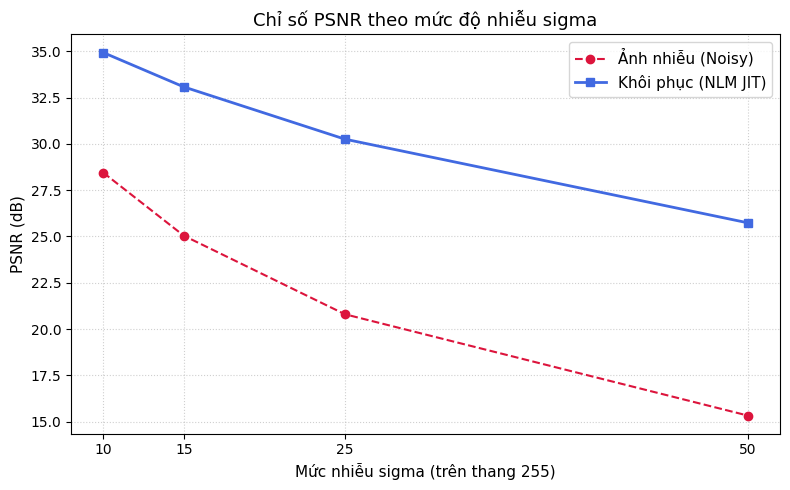

In [32]:
# Vòng lặp qua sigma trong {10, 15, 25, 50}
sigma_values = [10, 15, 25, 50]
psnr_noisy_list = []
psnr_denoised_list = []

for sig in sigma_values:
    sig_norm = sig / 255.0
    noisy = add_awgn(clean_img, sigma=sig_norm, seed=42)
    h_opt = 1.0 * sig_norm
    denoised = nlm_denoise(noisy, f=2, t=5, h=h_opt, sigma=sig_norm, backend="jit")
    
    p_noisy = psnr(clean_img, noisy)
    p_denoised = psnr(clean_img, denoised)
    psnr_noisy_list.append(p_noisy)
    psnr_denoised_list.append(p_denoised)
    print(f"Sigma = {sig:2d} | PSNR Nhiễu: {p_noisy:.2f} dB | PSNR Khôi phục: {p_denoised:.2f} dB (+{p_denoised - p_noisy:.2f} dB)")

# Vẽ biểu đồ PSNR theo sigma
plt.figure(figsize=(8, 5))
plt.plot(sigma_values, psnr_noisy_list, marker="o", linestyle="--", color="crimson", label="Ảnh nhiễu (Noisy)")
plt.plot(sigma_values, psnr_denoised_list, marker="s", linestyle="-", color="royalblue", linewidth=2, label="Khôi phục (NLM JIT)")
plt.title("Chỉ số PSNR theo mức độ nhiễu sigma", fontsize=13)
plt.xlabel("Mức nhiễu sigma (trên thang 255)", fontsize=11)
plt.ylabel("PSNR (dB)", fontsize=11)
plt.xticks(sigma_values)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()